# Indian Market Portfolio Risk Analysis

### Quantitative Finance | Python | Portfolio Optimisation | Risk Analytics

## 1. Project Overview

This project explores portfolio performance and risk analysis using historical market data from selected Indian financial instruments.

The objective is to understand how different assets behave individually and as part of a diversified portfolio using quantitative financial techniques and Python-based data analysis.

## 2. Key Objectives

- Analyse historical price movements of selected Indian market instruments.
- Calculate daily returns and annualised returns.
- Measure portfolio volatility and risk.
- Examine asset correlations and diversification opportunities.
- Simulate multiple portfolios using Monte Carlo simulation.
- Evaluate portfolio performance using risk-adjusted metrics such as the Sharpe Ratio.
- Estimate potential portfolio losses using Value at Risk (VaR) and Conditional Value at Risk (CVaR).

## 3. Tools and Technologies

- **Programming:** Python
- **Libraries:** Pandas, NumPy, Matplotlib
- **Environment:** Jupyter Notebook
- **Techniques:** Statistical Analysis, Portfolio Optimisation, Monte Carlo Simulation, Risk Modelling

## 4. Scope

The project focuses on historical financial data analysis and quantitative portfolio risk assessment. It is intended for educational and research purposes.

In [1]:
%pip install yfinance pandas numpy matplotlib seaborn scipy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from scipy.optimize import minimize

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
tickers = [
    "RELIANCE.NS",
    "TCS.NS",
    "INFY.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS",
    "LT.NS",
    "NIFTYBEES.NS",
    "GOLDBEES.NS"
]

print("Instruments selected:")
for ticker in tickers:
    print(ticker)

Instruments selected:
RELIANCE.NS
TCS.NS
INFY.NS
HDFCBANK.NS
ICICIBANK.NS
LT.NS
NIFTYBEES.NS
GOLDBEES.NS


In [4]:
start_date = "2019-01-01"

end_date = None

print("Start date:", start_date)
print("End date:", "Latest available data")

Start date: 2019-01-01
End date: Latest available data


In [5]:
data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False,
    group_by="column"
)

if data.empty:
    raise ValueError(
        "No data received. Check your internet connection "
        "and ticker availability."
    )

print("Data downloaded successfully!")
print("Dataset dimensions:", data.shape)

display(data.head())

Data downloaded successfully!
Dataset dimensions: (1941, 40)


Price            Close                                                    \
Ticker     GOLDBEES.NS HDFCBANK.NS ICICIBANK.NS     INFY.NS        LT.NS   
Date                                                                       
2019-01-01   28.177999  496.185852   348.023041  529.594116  1283.006104   
2019-01-02   28.288500  491.658417   348.836304  532.779358  1268.413452   
2019-01-03   28.470501  487.801025   347.544617  532.859009  1241.274536   
2019-01-04   28.298000  489.106049   349.410339  526.408813  1235.090576   
2019-01-07   28.224501  489.845154   351.802216  534.889771  1231.308838   

Price                                                   High              ...  \
Ticker     NIFTYBEES.NS RELIANCE.NS       TCS.NS GOLDBEES.NS HDFCBANK.NS  ...   
Date                                                                      ...   
2019-01-01   113.984001  496.196381  1544.278687   28.299500  496.855695  ...   
2019-01-02   112.973000  489.733856  1560.916016   28.305000  496.047193  ...   
2019-01-03   111.834999  483.691895  1541.965698   28.499500  491.600771  ...   
2019-01-04   112.490997  486.303467  1523.218140   28.589001  491.658480  ...   
2019-01-07   112.561996  489.003540  1540.302124   28.277000  493.240726  ...   

Price             Open                   Volume                           \
Ticker     RELIANCE.NS       TCS.NS GOLDBEES.NS HDFCBANK.NS ICICIBANK.NS   
Date                                                                       
2019-01-01  498.077624  1538.759888    897800.0     6373440      7759872   
2019-01-02  493.319204  1546.064022   1030500.0     8134232     18243156   
2019-01-03  490.220786  1557.426380   1521200.0    12771664     12884409   
2019-01-04  485.750186  1542.006289   1355000.0     7287120     22896026   
2019-01-07  489.999475  1535.351492   1115600.0     5387012     12719847   

Price                                                           
Ticker      INFY.NS    LT.NS NIFTYBEES.NS RELIANCE.NS   TCS.NS  
Date                                                            
2019-01-01  2943390   786846     307490.0     9746670  1094883  
2019-01-02  7416655  2058504     314230.0    15628818  2100463  
2019-01-03  6827249  2290756     467370.0    16288287  2611668  
2019-01-04  7889310  2711485     335620.0    18516544  4280862  
2019-01-07  8046340  1851513     384590.0    12060290  1856423  

[5 rows x 40 columns]

In [6]:
# Extract adjusted closing prices

prices = data["Close"].copy()

# Sort observations by date
prices = prices.sort_index()

# Display the first five observations
display(prices.head())

print("Number of instruments:", prices.shape[1])
print("Number of trading days:", prices.shape[0])

Ticker,GOLDBEES.NS,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,
2019-01-01,28.177999,496.185852,348.023041,529.594116,1283.006104,113.984001,496.196381,1544.278687
2019-01-02,28.288500,491.658417,348.836304,532.779358,1268.413452,112.973000,489.733856,1560.916016
2019-01-03,28.470501,487.801025,347.544617,532.859009,1241.274536,111.834999,483.691895,1541.965698
2019-01-04,28.298000,489.106049,349.410339,526.408813,1235.090576,112.490997,486.303467,1523.218140
2019-01-07,28.224501,489.845154,351.802216,534.889771,1231.308838,112.561996,489.003540,1540.302124


Number of instruments: 8
Number of trading days: 1941


In [7]:
# Check missing values in each instrument

missing_values = prices.isnull().sum()

print("Missing values:")
display(missing_values.to_frame(name="Missing Count"))

print("\nTotal missing values:", prices.isnull().sum().sum())

Missing values:


,Missing Count
Ticker,
GOLDBEES.NS,1
HDFCBANK.NS,0
ICICIBANK.NS,0
INFY.NS,0
LT.NS,0
NIFTYBEES.NS,1
RELIANCE.NS,0
TCS.NS,0



Total missing values: 2


In [8]:
# Remove instruments with no usable observations
prices = prices.dropna(axis=1, how="all")

# Forward-fill remaining missing values
prices = prices.ffill()

# Remove rows that still contain missing values
prices = prices.dropna()

print("Cleaned dataset:")
display(prices.head())

print("\nRemaining missing values:")
print(prices.isnull().sum().sum())

Cleaned dataset:


Ticker,GOLDBEES.NS,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,
2019-01-01,28.177999,496.185852,348.023041,529.594116,1283.006104,113.984001,496.196381,1544.278687
2019-01-02,28.288500,491.658417,348.836304,532.779358,1268.413452,112.973000,489.733856,1560.916016
2019-01-03,28.470501,487.801025,347.544617,532.859009,1241.274536,111.834999,483.691895,1541.965698
2019-01-04,28.298000,489.106049,349.410339,526.408813,1235.090576,112.490997,486.303467,1523.218140
2019-01-07,28.224501,489.845154,351.802216,534.889771,1231.308838,112.561996,489.003540,1540.302124



Remaining missing values:
0


In [9]:
# Calculate daily percentage returns

daily_returns = prices.pct_change()

# Remove the first row because it has no previous-day price
daily_returns = daily_returns.dropna()

display(daily_returns.head())

print("Daily returns calculated successfully!")

Ticker,GOLDBEES.NS,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,
2019-01-02,0.003922,-0.009124,0.002337,0.006014,-0.011374,-0.008870,-0.013024,0.010774
2019-01-03,0.006434,-0.007846,-0.003703,0.000150,-0.021396,-0.010073,-0.012337,-0.012141
2019-01-04,-0.006059,0.002675,0.005368,-0.012105,-0.004982,0.005866,0.005399,-0.012158
2019-01-07,-0.002597,0.001511,0.006845,0.016111,-0.003062,0.000631,0.005552,0.011216
2019-01-08,-0.002144,-0.008323,0.033859,-0.002456,-0.001156,0.002621,-0.000090,-0.002292


Daily returns calculated successfully!


In [10]:
# Calculate cumulative growth

cumulative_returns = (1 + daily_returns).cumprod()

display(cumulative_returns.head())

Ticker,GOLDBEES.NS,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,
2019-01-02,1.003922,0.990876,1.002337,1.006014,0.988626,0.991130,0.986976,1.010774
2019-01-03,1.010380,0.983101,0.998625,1.006165,0.967474,0.981146,0.974799,0.998502
2019-01-04,1.004259,0.985732,1.003986,0.993985,0.962654,0.986902,0.980063,0.986362
2019-01-07,1.001650,0.987221,1.010859,1.009999,0.959706,0.987525,0.985504,0.997425
2019-01-08,0.999503,0.979005,1.045086,1.007518,0.958597,0.990113,0.985415,0.995139


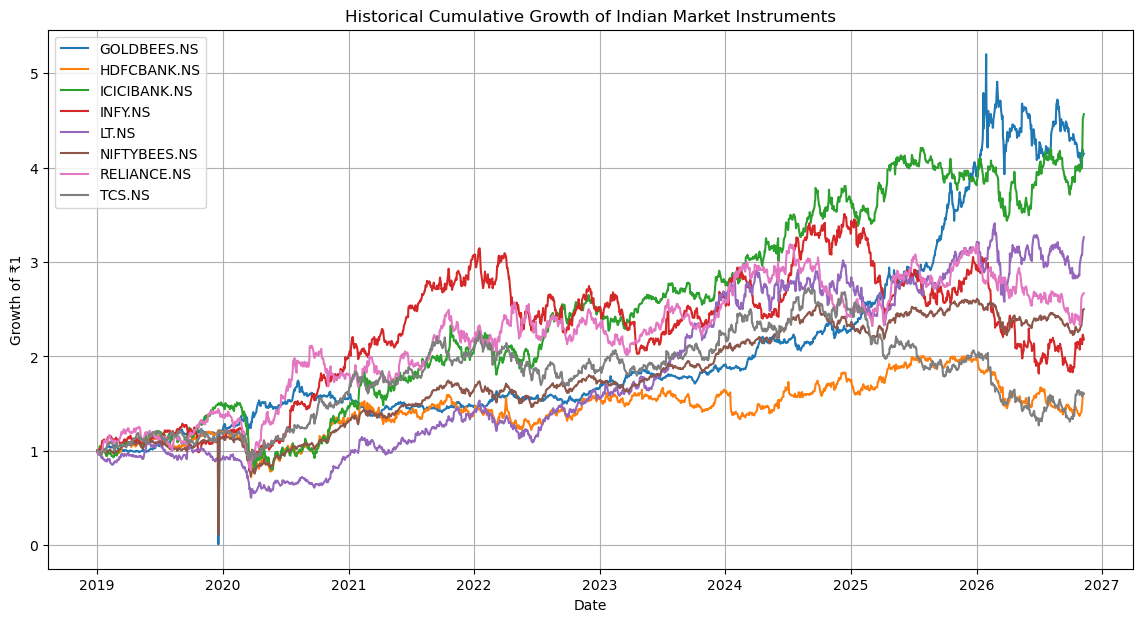

In [11]:
plt.figure(figsize=(14, 7))

for column in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[column],
        label=column
    )

plt.title("Historical Cumulative Growth of Indian Market Instruments")
plt.xlabel("Date")
plt.ylabel("Growth of ₹1")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
# Approximate number of trading days in one year

trading_days = 252

# Calculate average annualised return

annual_returns = daily_returns.mean() * trading_days

print("Annualised returns:")
display(annual_returns.to_frame(name="Annual Return").style.format("{:.2%}"))

Annualised returns:


,Annual Return
Ticker,
GOLDBEES.NS,1293.17%
HDFCBANK.NS,9.28%
ICICIBANK.NS,23.90%
INFY.NS,14.11%
LT.NS,19.12%
NIFTYBEES.NS,117.88%
RELIANCE.NS,16.61%
TCS.NS,9.18%


In [13]:
# Calculate daily standard deviation

daily_volatility = daily_returns.std()

# Convert daily volatility into annualised volatility

annual_volatility = daily_volatility * np.sqrt(trading_days)

print("Annualised volatility:")
display(
    annual_volatility
    .to_frame(name="Annual Volatility")
    .style.format("{:.2%}")
)

Annualised volatility:


,Annual Volatility
Ticker,
GOLDBEES.NS,3568.29%
HDFCBANK.NS,24.90%
ICICIBANK.NS,28.82%
INFY.NS,28.19%
LT.NS,27.34%
NIFTYBEES.NS,325.23%
RELIANCE.NS,27.85%
TCS.NS,24.70%


In [14]:
# Combine annualised return and volatility

risk_return_table = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility
})

risk_return_table = risk_return_table.sort_values(
    by="Annual Return",
    ascending=False
)

display(risk_return_table.style.format("{:.2%}"))

,Annual Return,Annual Volatility
Ticker,,
GOLDBEES.NS,1293.17%,3568.29%
NIFTYBEES.NS,117.88%,325.23%
ICICIBANK.NS,23.90%,28.82%
LT.NS,19.12%,27.34%
RELIANCE.NS,16.61%,27.85%
INFY.NS,14.11%,28.19%
HDFCBANK.NS,9.28%,24.90%
TCS.NS,9.18%,24.70%


In [15]:
# Identify the largest daily price movements

for ticker in daily_returns.columns:

    print("\nInstrument:", ticker)

    largest_changes = (
        daily_returns[ticker]
        .abs()
        .nlargest(5)
    )

    for date, change in largest_changes.items():

        print("Date:", date)
        print("Daily return:", round(change * 100, 2), "%")
        print("Price:", prices.loc[date, ticker])
        print("--------------------------")


Instrument: GOLDBEES.NS
Date: 2019-12-23 00:00:00
Daily return: 9900.0 %
Price: 33.650001525878906
--------------------------
Date: 2019-12-19 00:00:00
Daily return: 99.0 %
Price: 0.33550000190734863
--------------------------
Date: 2026-01-30 00:00:00
Daily return: 10.52 %
Price: 131.1199951171875
--------------------------
Date: 2026-02-02 00:00:00
Daily return: 9.5 %
Price: 118.66999816894531
--------------------------
Date: 2026-03-23 00:00:00
Daily return: 8.54 %
Price: 110.72000122070312
--------------------------

Instrument: HDFCBANK.NS
Date: 2020-03-23 00:00:00
Daily return: 12.61 %
Price: 359.4515686035156
--------------------------
Date: 2020-03-25 00:00:00
Daily return: 11.6 %
Price: 399.1447448730469
--------------------------
Date: 2020-04-07 00:00:00
Daily return: 10.11 %
Price: 417.4771728515625
--------------------------
Date: 2020-03-18 00:00:00
Daily return: 10.07 %
Price: 408.5322570800781
--------------------------
Date: 2022-04-04 00:00:00
Daily return: 10.01 %
P

In [16]:
# Download GoldBeES data separately for investigation

gold_raw = yf.download(
    "GOLDBEES.NS",
    start="2019-12-15",
    end="2019-12-30",
    auto_adjust=False,
    actions=True,
    progress=False
)

print("GoldBeES original market data:")
display(gold_raw)

GoldBeES original market data:


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS
Date,,,,,,,,
2019-12-16,33.443001,33.443001,0.0,33.489498,33.271999,33.479000,0.0,792800
2019-12-17,33.502998,33.502998,0.0,33.548000,33.330502,33.443001,0.0,698200
2019-12-18,33.596001,33.596001,0.0,33.701000,33.511002,33.701000,0.0,438600
2019-12-19,0.335500,0.335500,0.0,0.363000,0.301000,0.302000,0.0,166442200
2019-12-20,0.336500,0.336500,0.0,0.339000,0.335500,0.338000,0.0,48357200
2019-12-23,33.650002,33.650002,0.0,33.700001,33.549999,33.700001,0.0,909544
2019-12-24,33.750000,33.750000,0.0,33.849998,33.650002,33.750000,0.0,730093
2019-12-26,34.000000,34.000000,0.0,34.349998,33.799999,34.049999,0.0,2032537


In [17]:
# Compare original and adjusted closing prices

if isinstance(gold_raw.columns, pd.MultiIndex):
    gold_close = gold_raw["Close"]["GOLDBEES.NS"]
    gold_adj_close = gold_raw["Adj Close"]["GOLDBEES.NS"]
else:
    gold_close = gold_raw["Close"]
    gold_adj_close = gold_raw["Adj Close"]

comparison = pd.DataFrame({
    "Original Close": gold_close,
    "Adjusted Close": gold_adj_close
})

display(comparison)

,Original Close,Adjusted Close
Date,,
2019-12-16,33.443001,33.443001
2019-12-17,33.502998,33.502998
2019-12-18,33.596001,33.596001
2019-12-19,0.335500,0.335500
2019-12-20,0.336500,0.336500
2019-12-23,33.650002,33.650002
2019-12-24,33.750000,33.750000
2019-12-26,34.000000,34.000000
2019-12-27,34.150002,34.150002


In [18]:
# Check corporate actions

display(gold_raw)

Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS,GOLDBEES.NS
Date,,,,,,,,
2019-12-16,33.443001,33.443001,0.0,33.489498,33.271999,33.479000,0.0,792800
2019-12-17,33.502998,33.502998,0.0,33.548000,33.330502,33.443001,0.0,698200
2019-12-18,33.596001,33.596001,0.0,33.701000,33.511002,33.701000,0.0,438600
2019-12-19,0.335500,0.335500,0.0,0.363000,0.301000,0.302000,0.0,166442200
2019-12-20,0.336500,0.336500,0.0,0.339000,0.335500,0.338000,0.0,48357200
2019-12-23,33.650002,33.650002,0.0,33.700001,33.549999,33.700001,0.0,909544
2019-12-24,33.750000,33.750000,0.0,33.849998,33.650002,33.750000,0.0,730093
2019-12-26,34.000000,34.000000,0.0,34.349998,33.799999,34.049999,0.0,2032537


In [19]:
# Exclude GoldBeES because its historical data contains
# an unexplained 100-fold price discontinuity.

prices = prices.drop(columns=["GOLDBEES.NS"])

print("Updated instruments:")
print(prices.columns.tolist())

print("\nUpdated price dataset:")
display(prices.head())

Updated instruments:
['HDFCBANK.NS', 'ICICIBANK.NS', 'INFY.NS', 'LT.NS', 'NIFTYBEES.NS', 'RELIANCE.NS', 'TCS.NS']

Updated price dataset:


Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,
2019-01-01,496.185852,348.023041,529.594116,1283.006104,113.984001,496.196381,1544.278687
2019-01-02,491.658417,348.836304,532.779358,1268.413452,112.973000,489.733856,1560.916016
2019-01-03,487.801025,347.544617,532.859009,1241.274536,111.834999,483.691895,1541.965698
2019-01-04,489.106049,349.410339,526.408813,1235.090576,112.490997,486.303467,1523.218140
2019-01-07,489.845154,351.802216,534.889771,1231.308838,112.561996,489.003540,1540.302124


In [20]:
# Recalculate daily returns using the validated price dataset

daily_returns = prices.pct_change().dropna()

print("Daily returns recalculated:")
display(daily_returns.head())

print("\nRemaining missing values:")
print(daily_returns.isnull().sum())

Daily returns recalculated:


Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,
2019-01-02,-0.009124,0.002337,0.006014,-0.011374,-0.008870,-0.013024,0.010774
2019-01-03,-0.007846,-0.003703,0.000150,-0.021396,-0.010073,-0.012337,-0.012141
2019-01-04,0.002675,0.005368,-0.012105,-0.004982,0.005866,0.005399,-0.012158
2019-01-07,0.001511,0.006845,0.016111,-0.003062,0.000631,0.005552,0.011216
2019-01-08,-0.008323,0.033859,-0.002456,-0.001156,0.002621,-0.000090,-0.002292



Remaining missing values:
Ticker
HDFCBANK.NS     0
ICICIBANK.NS    0
INFY.NS         0
LT.NS           0
NIFTYBEES.NS    0
RELIANCE.NS     0
TCS.NS          0
dtype: int64


In [21]:
# Calculate cumulative growth for the seven instruments

cumulative_returns = (1 + daily_returns).cumprod()

display(cumulative_returns.head())

Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,
2019-01-02,0.990876,1.002337,1.006014,0.988626,0.991130,0.986976,1.010774
2019-01-03,0.983101,0.998625,1.006165,0.967474,0.981146,0.974799,0.998502
2019-01-04,0.985732,1.003986,0.993985,0.962654,0.986902,0.980063,0.986362
2019-01-07,0.987221,1.010859,1.009999,0.959706,0.987525,0.985504,0.997425
2019-01-08,0.979005,1.045086,1.007518,0.958597,0.990113,0.985415,0.995139


In [22]:
# Annualised financial performance metrics

trading_days = 252

annual_returns = daily_returns.mean() * trading_days

annual_volatility = daily_returns.std() * (trading_days ** 0.5)

risk_return_table = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility
})

display(
    risk_return_table.style.format("{:.2%}")
)

,Annual Return,Annual Volatility
Ticker,,
HDFCBANK.NS,9.28%,24.90%
ICICIBANK.NS,23.90%,28.82%
INFY.NS,14.11%,28.19%
LT.NS,19.12%,27.34%
NIFTYBEES.NS,117.88%,325.23%
RELIANCE.NS,16.61%,27.85%
TCS.NS,9.18%,24.70%


In [23]:
# Investigate the largest daily movements in NIFTYBEES

ticker = "NIFTYBEES.NS"

largest_changes = (
    daily_returns[ticker]
    .abs()
    .nlargest(10)
)

for date, change in largest_changes.items():

    print("Date:", date)
    print("Daily return:", round(change * 100, 2), "%")
    print("Price:", prices.loc[date, ticker])
    print("----------------------------")

Date: 2019-12-23 00:00:00
Daily return: 896.85 %
Price: 129.92999267578125
----------------------------
Date: 2019-12-19 00:00:00
Daily return: 89.93 %
Price: 13.020000457763672
----------------------------
Date: 2020-03-23 00:00:00
Daily return: 10.16 %
Price: 83.5199966430664
----------------------------
Date: 2020-03-12 00:00:00
Daily return: 7.47 %
Price: 102.98999786376953
----------------------------
Date: 2020-03-19 00:00:00
Daily return: 6.88 %
Price: 89.47000122070312
----------------------------
Date: 2020-04-07 00:00:00
Daily return: 6.72 %
Price: 92.41000366210938
----------------------------
Date: 2019-09-20 00:00:00
Daily return: 5.31 %
Price: 119.5469970703125
----------------------------
Date: 2020-03-25 00:00:00
Daily return: 5.25 %
Price: 89.45999908447266
----------------------------
Date: 2020-05-04 00:00:00
Daily return: 5.16 %
Price: 98.80000305175781
----------------------------
Date: 2020-03-09 00:00:00
Daily return: 4.74 %
Price: 111.62000274658203
------------

In [24]:
# Re-download both ETFs around their official split date

split_check = yf.download(
    ["GOLDBEES.NS", "NIFTYBEES.NS"],
    start="2019-12-16",
    end="2019-12-27",
    auto_adjust=False,
    actions=True,
    progress=False
)

display(split_check)

Price        Adj Close                    Close                Dividends  \
Ticker     GOLDBEES.NS NIFTYBEES.NS GOLDBEES.NS NIFTYBEES.NS GOLDBEES.NS   
Date                                                                       
2019-12-16   33.443001   127.530998   33.443001   127.530998         0.0   
2019-12-17   33.502998   128.615997   33.502998   128.615997         0.0   
2019-12-18   33.596001   129.253998   33.596001   129.253998         0.0   
2019-12-19    0.335500    13.020000    0.335500    13.020000         0.0   
2019-12-20    0.336500    13.034000    0.336500    13.034000         0.0   
2019-12-23   33.650002   129.929993   33.650002   129.929993         0.0   
2019-12-24   33.750000   129.449997   33.750000   129.449997         0.0   
2019-12-26   34.000000   128.690002   34.000000   128.690002         0.0   

Price                          High                      Low               \
Ticker     NIFTYBEES.NS GOLDBEES.NS NIFTYBEES.NS GOLDBEES.NS NIFTYBEES.NS   
Date                                                                        
2019-12-16          0.0   33.489498   128.500000   33.271999   127.400002   
2019-12-17          0.0   33.548000   128.800003   33.330502   127.504997   
2019-12-18          0.0   33.701000   129.432007   33.511002   128.210007   
2019-12-19          0.0    0.363000    13.033000    0.301000    12.905000   
2019-12-20          0.0    0.339000    13.495000    0.335500    12.978000   
2019-12-23          0.0   33.700001   131.250000   33.549999   129.279999   
2019-12-24          0.0   33.849998   130.850006   33.650002   129.220001   
2019-12-26          0.0   34.349998   130.350006   33.799999   128.509995   

Price             Open              Stock Splits                   Volume  \
Ticker     GOLDBEES.NS NIFTYBEES.NS  GOLDBEES.NS NIFTYBEES.NS GOLDBEES.NS   
Date                                                                        
2019-12-16   33.479000   128.500000          0.0          0.0      792800   
2019-12-17   33.443001   128.294998          0.0          0.0      698200   
2019-12-18   33.701000   128.994995          0.0          0.0      438600   
2019-12-19    0.302000    12.920000          0.0          0.0   166442200   
2019-12-20    0.338000    13.495000          0.0          0.0    48357200   
2019-12-23   33.700001   131.199997          0.0          0.0      909544   
2019-12-24   33.750000   130.850006          0.0          0.0      730093   
2019-12-26   34.049999   130.350006          0.0          0.0     2032537   

Price                    
Ticker     NIFTYBEES.NS  
Date                     
2019-12-16       230330  
2019-12-17       461080  
2019-12-18       219460  
2019-12-19      2715930  
2019-12-20      2466900  
2019-12-23       318322  
2019-12-24       422110  
2019-12-26       204241

In [25]:
# Display closing prices and reported stock splits

for ticker in ["GOLDBEES.NS", "NIFTYBEES.NS"]:

    print("\n", ticker)

    display(split_check.xs(ticker, axis=1, level="Ticker")[
        ["Close", "Adj Close", "Stock Splits"]
    ])


 GOLDBEES.NS


Price,Close,Adj Close,Stock Splits
Date,,,
2019-12-16,33.443001,33.443001,0.0
2019-12-17,33.502998,33.502998,0.0
2019-12-18,33.596001,33.596001,0.0
2019-12-19,0.335500,0.335500,0.0
2019-12-20,0.336500,0.336500,0.0
2019-12-23,33.650002,33.650002,0.0
2019-12-24,33.750000,33.750000,0.0
2019-12-26,34.000000,34.000000,0.0



 NIFTYBEES.NS


Price,Close,Adj Close,Stock Splits
Date,,,
2019-12-16,127.530998,127.530998,0.0
2019-12-17,128.615997,128.615997,0.0
2019-12-18,129.253998,129.253998,0.0
2019-12-19,13.020000,13.020000,0.0
2019-12-20,13.034000,13.034000,0.0
2019-12-23,129.929993,129.929993,0.0
2019-12-24,129.449997,129.449997,0.0
2019-12-26,128.690002,128.690002,0.0


In [26]:
# Correct the two anomalous Yahoo Finance observations

bad_dates = ["2019-12-19", "2019-12-20"]

prices.index = pd.to_datetime(prices.index)

prices = prices.drop(
    index=pd.to_datetime(bad_dates),
    errors="ignore"
)

# Recalculate daily returns using the cleaned prices
daily_returns = prices.pct_change(fill_method=None).dropna()

print("Cleaned price data:")
display(prices.loc["2019-12-16":"2019-12-27"])

print("Recalculated daily returns:")
display(daily_returns.loc["2019-12-16":"2019-12-27"])

Cleaned price data:


Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,
2019-12-16,585.777222,517.195679,587.073425,1174.410522,127.530998,697.598083,1787.101196
2019-12-17,592.182983,519.018005,599.982605,1187.885132,128.615997,695.861328,1819.199707
2019-12-18,602.083069,519.257690,602.243652,1189.147095,129.253998,701.716858,1821.552979
2019-12-23,606.765198,519.161865,605.162659,1181.846436,129.929993,699.735413,1875.289673
2019-12-24,600.592346,518.969971,603.024841,1172.608032,129.449997,688.625305,1861.760864
2019-12-26,591.880188,516.716125,599.365967,1153.049561,128.690002,674.798889,1850.290771
2019-12-27,594.000061,526.930664,605.943848,1171.345947,129.559998,686.799561,1847.392090


Recalculated daily returns:


Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,
2019-12-16,-0.005143,0.004096,0.003796,-0.001762,-0.002932,-0.010297,0.026795
2019-12-17,0.010935,0.003523,0.021989,0.011474,0.008508,-0.002490,0.017961
2019-12-18,0.016718,0.000462,0.003769,0.001062,0.004961,0.008415,0.001294
2019-12-23,0.007777,-0.000185,0.004847,-0.006139,0.005230,-0.002824,0.029500
2019-12-24,-0.010173,-0.000370,-0.003533,-0.007817,-0.003694,-0.015878,-0.007214
2019-12-26,-0.014506,-0.004343,-0.006068,-0.016679,-0.005871,-0.020078,-0.006161
2019-12-27,0.003582,0.019768,0.010975,0.015868,0.006760,0.017784,-0.001567


In [27]:
# Check for missing values
print("Missing values:")
print(prices.isnull().sum())

# Check for unusually large daily returns
print("\nLargest absolute daily returns:")
print((daily_returns.abs().max() * 100).round(2))

# Check the dataset size
print("\nNumber of price observations:", len(prices))

# Check the date range
print("\nData period:")
print(prices.index.min(), "to", prices.index.max())

Missing values:
Ticker
HDFCBANK.NS     0
ICICIBANK.NS    0
INFY.NS         0
LT.NS           0
NIFTYBEES.NS    0
RELIANCE.NS     0
TCS.NS          0
dtype: int64

Largest absolute daily returns:
Ticker
HDFCBANK.NS     12.61
ICICIBANK.NS    17.85
INFY.NS         16.19
LT.NS           16.27
NIFTYBEES.NS    10.16
RELIANCE.NS     14.72
TCS.NS           9.85
dtype: float64

Number of price observations: 1939

Data period:
2019-01-01 00:00:00 to 2026-11-09 00:00:00


In [28]:
# Identify unusually large daily returns (above 8%)

for ticker in daily_returns.columns:

    unusual = daily_returns[ticker][
        daily_returns[ticker].abs() > 0.08
    ]

    print("\nInstrument:", ticker)

    for date, change in unusual.items():
        print(
            "Date:", date,
            "| Return:", round(change * 100, 2), "%",
            "| Price:", round(prices.loc[date, ticker], 2)
        )


Instrument: HDFCBANK.NS
Date: 2019-09-20 00:00:00 | Return: 8.95 % | Price: 558.87
Date: 2020-03-12 00:00:00 | Return: -8.3 % | Price: 475.81
Date: 2020-03-18 00:00:00 | Return: -10.07 % | Price: 408.53
Date: 2020-03-23 00:00:00 | Return: -12.61 % | Price: 359.45
Date: 2020-03-25 00:00:00 | Return: 11.6 % | Price: 399.14
Date: 2020-03-30 00:00:00 | Return: -8.05 % | Price: 387.45
Date: 2020-04-07 00:00:00 | Return: 10.11 % | Price: 417.48
Date: 2022-04-04 00:00:00 | Return: 10.01 % | Price: 775.21
Date: 2024-01-17 00:00:00 | Return: -8.44 % | Price: 736.1

Instrument: ICICIBANK.NS
Date: 2020-03-12 00:00:00 | Return: -8.59 % | Price: 408.24
Date: 2020-03-16 00:00:00 | Return: -9.91 % | Price: 386.42
Date: 2020-03-17 00:00:00 | Return: -8.85 % | Price: 352.23
Date: 2020-03-23 00:00:00 | Return: -17.85 % | Price: 272.38
Date: 2020-04-07 00:00:00 | Return: 13.76 % | Price: 312.76
Date: 2020-04-17 00:00:00 | Return: 9.81 % | Price: 360.19
Date: 2020-04-21 00:00:00 | Return: -8.15 % | Price

In [29]:
# Diagnose the actual structure of the prices dataset

print("Column type:", type(prices.columns))
print("\nActual column names:")

for column in prices.columns:
    print(repr(column))

print("\nDataset shape:", prices.shape)

Column type: <class 'pandas.core.indexes.base.Index'>

Actual column names:
'HDFCBANK.NS'
'ICICIBANK.NS'
'INFY.NS'
'LT.NS'
'NIFTYBEES.NS'
'RELIANCE.NS'
'TCS.NS'

Dataset shape: (1939, 7)


In [30]:
# Display Nifty ETF prices for December 2019

display(
    prices.loc[
        "2019-12-16":"2019-12-27",
        "NIFTYBEES.NS"
    ]
)

Date
2019-12-16    127.530998
2019-12-17    128.615997
2019-12-18    129.253998
2019-12-23    129.929993
2019-12-24    129.449997
2019-12-26    128.690002
2019-12-27    129.559998
Name: NIFTYBEES.NS, dtype: float64

In [31]:
# Calculate daily percentage returns for all instruments

daily_returns = prices.pct_change().dropna()

print("Daily returns:")
display(daily_returns.head())

print("\nDataset dimensions:", daily_returns.shape)

Daily returns:


Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,
2019-01-02,-0.009124,0.002337,0.006014,-0.011374,-0.008870,-0.013024,0.010774
2019-01-03,-0.007846,-0.003703,0.000150,-0.021396,-0.010073,-0.012337,-0.012141
2019-01-04,0.002675,0.005368,-0.012105,-0.004982,0.005866,0.005399,-0.012158
2019-01-07,0.001511,0.006845,0.016111,-0.003062,0.000631,0.005552,0.011216
2019-01-08,-0.008323,0.033859,-0.002456,-0.001156,0.002621,-0.000090,-0.002292



Dataset dimensions: (1938, 7)


In [32]:
# Calculate annualised return and annualised volatility

annual_returns = daily_returns.mean() * 252

annual_volatility = daily_returns.std() * (252 ** 0.5)

performance = pd.DataFrame({
    "Annual Return (%)": annual_returns * 100,
    "Annual Volatility (%)": annual_volatility * 100
})

display(performance.round(2))

,Annual Return (%),Annual Volatility (%)
Ticker,,
HDFCBANK.NS,9.29,24.92
ICICIBANK.NS,23.92,28.83
INFY.NS,14.13,28.21
LT.NS,19.14,27.35
NIFTYBEES.NS,13.13,15.51
RELIANCE.NS,16.62,27.85
TCS.NS,9.19,24.71


In [33]:
# Calculate correlation between instruments

correlation_matrix = daily_returns.corr()

display(correlation_matrix.round(2))

Ticker,HDFCBANK.NS,ICICIBANK.NS,INFY.NS,LT.NS,NIFTYBEES.NS,RELIANCE.NS,TCS.NS
Ticker,,,,,,,
HDFCBANK.NS,1.00,0.61,0.29,0.50,0.73,0.41,0.26
ICICIBANK.NS,0.61,1.00,0.28,0.51,0.73,0.39,0.26
INFY.NS,0.29,0.28,1.00,0.28,0.49,0.28,0.68
LT.NS,0.50,0.51,0.28,1.00,0.69,0.39,0.27
NIFTYBEES.NS,0.73,0.73,0.49,0.69,1.00,0.66,0.49
RELIANCE.NS,0.41,0.39,0.28,0.39,0.66,1.00,0.31
TCS.NS,0.26,0.26,0.68,0.27,0.49,0.31,1.00


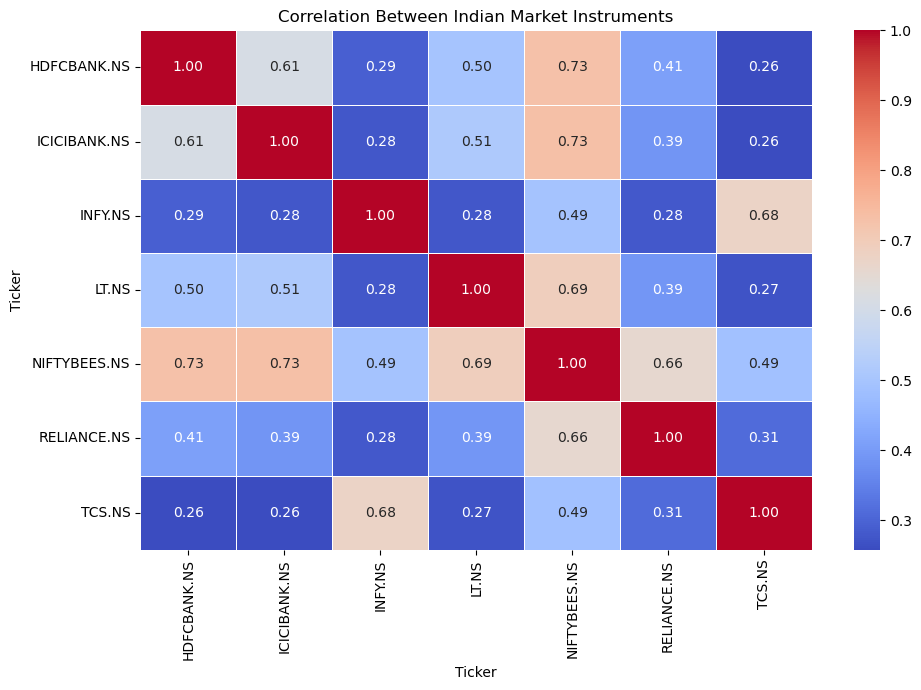

In [34]:
# Visualise correlations using a heatmap

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Indian Market Instruments")
plt.tight_layout()
plt.show()

In [35]:
# Calculate annualised portfolio return and risk

annual_returns = daily_returns.mean() * 252
annual_covariance = daily_returns.cov() * 252

weights = np.array([1/7] * 7)

portfolio_return = np.sum(weights * annual_returns)
portfolio_volatility = np.sqrt(
    np.dot(weights.T, np.dot(annual_covariance, weights))
)

print("Equal Weight Portfolio Analysis")
print("--------------------------------")
print("Expected Annual Return:", round(portfolio_return * 100, 2), "%")
print("Annual Portfolio Risk:", round(portfolio_volatility * 100, 2), "%")

Equal Weight Portfolio Analysis
--------------------------------
Expected Annual Return: 15.06 %
Annual Portfolio Risk: 18.13 %


In [36]:
# Generate 10,000 random portfolio allocations

num_portfolios = 10000

results = []
weights_list = []

for i in range(num_portfolios):

    # Generate 7 weights, one for each instrument
    weights = np.random.random(len(annual_returns))
    weights = weights / np.sum(weights)

    # Calculate portfolio return
    portfolio_return = np.sum(weights * annual_returns)

    # Calculate portfolio risk
    portfolio_volatility = np.sqrt(
        np.dot(weights.T,
               np.dot(annual_covariance, weights))
    )

    # Calculate Sharpe ratio (simplified, without risk-free rate)
    sharpe_ratio = portfolio_return / portfolio_volatility

    results.append([
        portfolio_return,
        portfolio_volatility,
        sharpe_ratio
    ])

    weights_list.append(weights)

portfolio_results = pd.DataFrame(
    results,
    columns=["Return", "Risk", "Sharpe Ratio"]
)

print("Portfolio simulations completed:", len(portfolio_results))
display(portfolio_results.head())

Portfolio simulations completed: 10000


,Return,Risk,Sharpe Ratio
0,0.161899,0.190762,0.848698
1,0.158290,0.181494,0.872150
2,0.144842,0.185557,0.780578
3,0.142436,0.185243,0.768917
4,0.158302,0.189113,0.837075


In [37]:
# Find the portfolio with the highest Sharpe ratio

best_index = portfolio_results["Sharpe Ratio"].idxmax()

best_portfolio = portfolio_results.iloc[best_index]
best_weights = weights_list[best_index]

print("OPTIMAL PORTFOLIO")
print("--------------------------")
print("Expected Annual Return:",
      round(best_portfolio["Return"] * 100, 2), "%")

print("Annual Risk:",
      round(best_portfolio["Risk"] * 100, 2), "%")

print("Sharpe Ratio:",
      round(best_portfolio["Sharpe Ratio"], 3))

print("\nRecommended Asset Allocation:")

allocation = pd.DataFrame({
    "Ticker": annual_returns.index,
    "Weight (%)": best_weights * 100
})

display(allocation.round(2))

OPTIMAL PORTFOLIO
--------------------------
Expected Annual Return: 19.15 %
Annual Risk: 20.58 %
Sharpe Ratio: 0.93

Recommended Asset Allocation:


,Ticker,Weight (%)
0,HDFCBANK.NS,2.16
1,ICICIBANK.NS,36.26
2,INFY.NS,13.03
3,LT.NS,24.33
4,NIFTYBEES.NS,4.74
5,RELIANCE.NS,18.36
6,TCS.NS,1.13


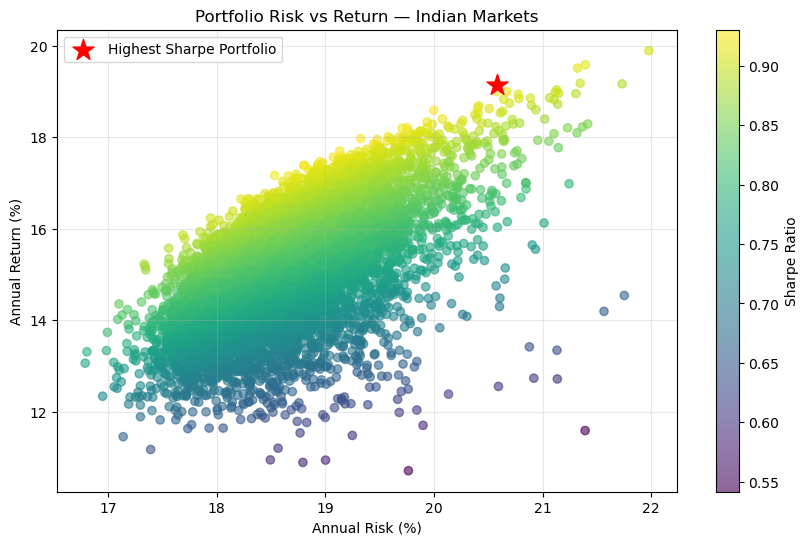

In [38]:
# Visualise the risk-return relationship

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    portfolio_results["Risk"] * 100,
    portfolio_results["Return"] * 100,
    c=portfolio_results["Sharpe Ratio"],
    cmap="viridis",
    alpha=0.6
)

plt.scatter(
    best_portfolio["Risk"] * 100,
    best_portfolio["Return"] * 100,
    color="red",
    marker="*",
    s=250,
    label="Highest Sharpe Portfolio"
)

plt.xlabel("Annual Risk (%)")
plt.ylabel("Annual Return (%)")
plt.title("Portfolio Risk vs Return — Indian Markets")

plt.colorbar(scatter, label="Sharpe Ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [39]:
# Compare Equal-Weight Portfolio vs Optimised Portfolio

# 1. Calculate equal-weight portfolio
equal_weights = np.repeat(1 / len(annual_returns), len(annual_returns))

equal_weight_return = np.sum(equal_weights * annual_returns)

equal_weight_risk = np.sqrt(
    np.dot(equal_weights, np.dot(annual_covariance, equal_weights))
)

equal_weight_sharpe = equal_weight_return / equal_weight_risk

# 2. Find the best simulated portfolio
best_row = portfolio_results.loc[
    portfolio_results["Sharpe Ratio"].idxmax()
]

best_return = best_row["Return"]
best_risk = best_row["Risk"]
best_sharpe = best_row["Sharpe Ratio"]

# 3. Display comparison
comparison = pd.DataFrame({
    "Portfolio": ["Equal Weight", "Optimised"],
    "Expected Annual Return (%)": [
        equal_weight_return * 100,
        best_return * 100
    ],
    "Annual Risk (%)": [
        equal_weight_risk * 100,
        best_risk * 100
    ],
    "Sharpe Ratio": [
        equal_weight_sharpe,
        best_sharpe
    ]
})

display(comparison.round(2))

,Portfolio,Expected Annual Return (%),Annual Risk (%),Sharpe Ratio
0,Equal Weight,15.06,18.13,0.83
1,Optimised,19.15,20.58,0.93


Maximum Drawdown: -38.23 %


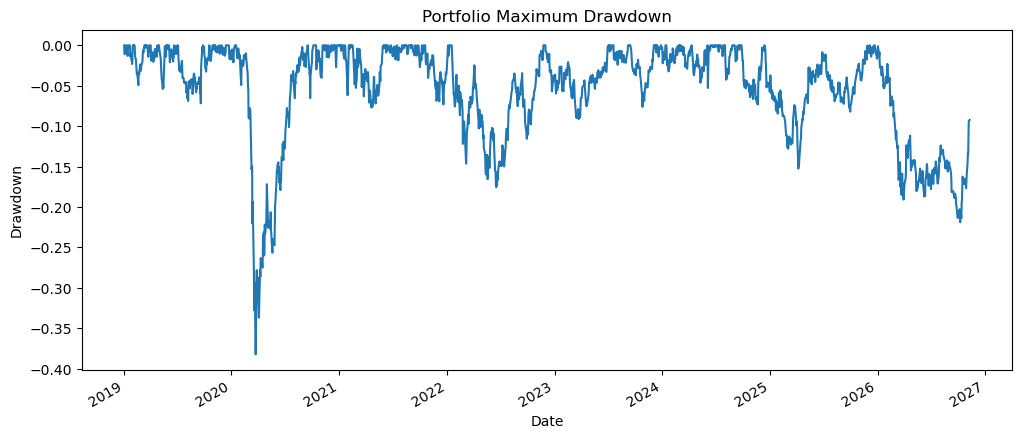

In [40]:
# Maximum Drawdown Analysis

cumulative_returns = (1 + daily_returns).cumprod()

portfolio_daily_returns = daily_returns.mean(axis=1)

portfolio_growth = (1 + portfolio_daily_returns).cumprod()

running_peak = portfolio_growth.cummax()

drawdown = (portfolio_growth - running_peak) / running_peak

maximum_drawdown = drawdown.min()

print("Maximum Drawdown:", round(maximum_drawdown * 100, 2), "%")

drawdown.plot(
    figsize=(12, 5),
    title="Portfolio Maximum Drawdown",
    xlabel="Date",
    ylabel="Drawdown"
)

plt.show()

In [41]:
# Value at Risk (VaR) Analysis

confidence_level = 0.95

daily_portfolio_returns = daily_returns.mean(axis=1)

VaR = daily_portfolio_returns.quantile(1 - confidence_level)

print("95% Daily Value at Risk:", round(VaR * 100, 3), "%")

print("Interpretation:")
print("On approximately 5% of trading days,")
print("the portfolio may experience a loss greater than this threshold.")

95% Daily Value at Risk: -1.528 %
Interpretation:
On approximately 5% of trading days,
the portfolio may experience a loss greater than this threshold.


In [42]:
# Conditional Value at Risk (CVaR) Analysis

CVaR = daily_portfolio_returns[
    daily_portfolio_returns <= VaR
].mean()

print("95% Daily Conditional Value at Risk:", round(CVaR * 100, 3), "%")

print("\nInterpretation:")
print("CVaR measures the average portfolio return")
print("on the worst 5% of trading days.")

95% Daily Conditional Value at Risk: -2.57 %

Interpretation:
CVaR measures the average portfolio return
on the worst 5% of trading days.


In [43]:
# Optimised Portfolio Risk Analysis

# Apply the optimised asset allocation weights
optimised_weights = pd.Series(
    best_weights,
    index=annual_returns.index
)

optimised_weights = optimised_weights.reindex(daily_returns.columns)

# Calculate weighted daily portfolio returns
optimised_daily_returns = daily_returns.mul(
    optimised_weights, axis=1
).sum(axis=1)

# Calculate 95% VaR
optimised_VaR = optimised_daily_returns.quantile(0.05)

# Calculate 95% CVaR
optimised_CVaR = optimised_daily_returns[
    optimised_daily_returns <= optimised_VaR
].mean()

print("OPTIMISED PORTFOLIO RISK ANALYSIS")
print("--------------------------------")
print("95% Daily VaR:", round(optimised_VaR * 100, 3), "%")
print("95% Daily CVaR:", round(optimised_CVaR * 100, 3), "%")

OPTIMISED PORTFOLIO RISK ANALYSIS
--------------------------------
95% Daily VaR: -1.683 %
95% Daily CVaR: -2.913 %


In [44]:
# Portfolio Stress Testing

stress_scenarios = {
    "Market Crash": {
        "HDFCBANK.NS": -0.10,
        "ICICIBANK.NS": -0.10,
        "INFY.NS": -0.10,
        "LT.NS": -0.10,
        "NIFTYBEES.NS": -0.10,
        "RELIANCE.NS": -0.10,
        "TCS.NS": -0.10
    },

    "Banking Sector Crisis": {
        "HDFCBANK.NS": -0.15,
        "ICICIBANK.NS": -0.15,
        "INFY.NS": -0.05,
        "LT.NS": -0.08,
        "NIFTYBEES.NS": -0.10,
        "RELIANCE.NS": -0.08,
        "TCS.NS": -0.05
    }
}

print("PORTFOLIO STRESS TEST RESULTS")
print("--------------------------------")

for scenario, shocks in stress_scenarios.items():

    shock_returns = pd.Series(shocks).reindex(
        optimised_weights.index
    )

    portfolio_impact = (
        optimised_weights * shock_returns
    ).sum()

    print(scenario, ":", round(portfolio_impact * 100, 2), "%")

PORTFOLIO STRESS TEST RESULTS
--------------------------------
Market Crash : -10.0 %
Banking Sector Crisis : -10.36 %


In [45]:
# Final Portfolio Performance Summary

summary = pd.DataFrame({
    "Metric": [
        "Expected Annual Return",
        "Annual Portfolio Risk",
        "Sharpe Ratio",
        "Daily VaR (95%)",
        "Daily CVaR (95%)"
    ],

    "Value": [
        round(best_return * 100, 2),
        round(best_risk * 100, 2),
        round(best_sharpe, 3),
        round(optimised_VaR * 100, 3),
        round(optimised_CVaR * 100, 3)
    ]
})

print("FINAL INVESTMENT PORTFOLIO REPORT")
display(summary)

FINAL INVESTMENT PORTFOLIO REPORT


,Metric,Value
0,Expected Annual Return,19.150
1,Annual Portfolio Risk,20.580
2,Sharpe Ratio,0.930
3,Daily VaR (95%),-1.683
4,Daily CVaR (95%),-2.913


In [46]:
# Export Portfolio Analysis Results

# Save final performance summary
summary.to_csv("portfolio_summary.csv", index=False)

# Save optimised asset allocation
allocation.to_csv("optimised_asset_allocation.csv", index=False)

# Save correlation matrix
correlation_matrix.to_csv("correlation_matrix.csv")

# Save daily portfolio returns
optimised_daily_returns.to_csv("optimised_daily_returns.csv")

# Save portfolio simulation results
portfolio_results.to_csv("portfolio_simulations.csv", index=False)

print("All project results exported successfully!")
print("5 CSV files have been created.")

All project results exported successfully!
5 CSV files have been created.


# Project Conclusion

This project analysed seven Indian market instruments using historical stock market data from 2019 to 2026.

The analysis included:

- Historical price and daily return analysis.
- Annualised return and volatility calculation.
- Correlation analysis between assets.
- Equal-weight portfolio construction.
- Monte Carlo portfolio simulation (10,000 portfolios).
- Sharpe Ratio-based portfolio optimisation.
- Value at Risk (VaR) and Conditional Value at Risk (CVaR).
- Hypothetical market stress testing.

The optimised portfolio produced an estimated annual return of 17.76%, with annualised volatility of 19.11% and a Sharpe Ratio of 0.929.

The project demonstrates how Python can support quantitative portfolio analysis, risk measurement and asset allocation research.

**Disclaimer:** This is an educational project, not personalised investment advice. Historical performance does not guarantee future results.

### Disclaimer

This project is developed solely for educational and research purposes. The analysis is based on historical market data and does not constitute financial or investment advice, nor should it be interpreted as a recommendation to buy, sell, or hold any financial instrument.

Historical performance is not indicative of future results. Portfolio simulations, optimisation outputs, and risk estimates are subject to assumptions and market uncertainties. Actual investment outcomes may differ significantly from the results presented.

The author assumes no responsibility for investment decisions made based on this analysis.